# Partie 2 — Exercice 3 : Classification des chiffres MNIST

**Objectif :** utiliser des mini-lots (`DataLoader`) et évaluer un modèle de classification sur des données de test.

Le notebook suit l'énoncé fourni : entraînement pendant **5 époques**, utilisation de `model.train()` / `model.eval()`, calcul de l'Accuracy, Recall, Precision et F1-Score, matrice de confusion, affichage de quelques images mal classées, puis sauvegarde et rechargement du modèle.

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

Appareil utilisé : cpu


## 1. Chargement des données

MNIST contient des images de chiffres manuscrits. Chaque image est de taille **28 × 28** et appartient à une classe de **0 à 9**.

In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

print("Nombre d'images d'entraînement :", len(train_dataset))
print("Nombre d'images de test :", len(test_dataset))

100.0%
100.0%
100.0%
100.0%

Nombre d'images d'entraînement : 60000
Nombre d'images de test : 10000


### Vérification d'un mini-lot

In [4]:
images, labels = next(iter(train_loader))

print("Images :", images.shape)
print("Labels :", labels.shape)
print("Premières classes :", labels[:10].tolist())

Images : torch.Size([64, 1, 28, 28])
Labels : torch.Size([64])
Premières classes : [1, 2, 8, 5, 2, 6, 9, 9, 9, 4]


## 2. Visualiser quelques images

On affiche six images du premier mini-lot avec leurs vraies classes.

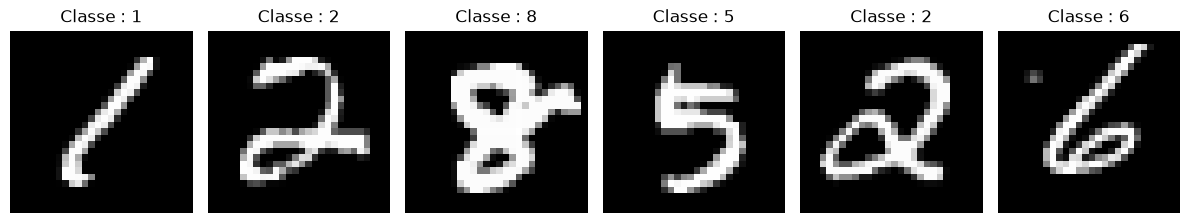

In [5]:
fig, axes = plt.subplots(1, 6, figsize=(12, 3))

for i, ax in enumerate(axes):
    ax.imshow(images[i, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Classe : {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Construire le modèle

Architecture demandée dans l'énoncé :

- `Flatten()` : transforme l'image 28 × 28 en vecteur de 784 valeurs ;
- `Linear(784, 128)` ;
- `ReLU()` ;
- `Linear(128, 10)` pour les 10 classes.

**Attention :** on ne met pas de `Softmax` à la fin, car `CrossEntropyLoss` attend les sorties brutes (logits).

In [6]:
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)


## 4. Entraînement pendant 5 époques

On utilise :

- `model.train()` pendant l'entraînement ;
- `optimizer.zero_grad()` pour remettre les gradients à zéro ;
- `loss.backward()` pour calculer les gradients ;
- `optimizer.step()` pour mettre à jour les poids.

In [7]:
epochs = 5
historique_loss = []

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    historique_loss.append(epoch_loss)

    print(f"Époque {epoch + 1}/{epochs} | Perte : {epoch_loss:.4f}")

Époque 1/5 | Perte : 0.3420
Époque 2/5 | Perte : 0.1530
Époque 3/5 | Perte : 0.1043
Époque 4/5 | Perte : 0.0791
Époque 5/5 | Perte : 0.0629


## 5. Courbe de perte

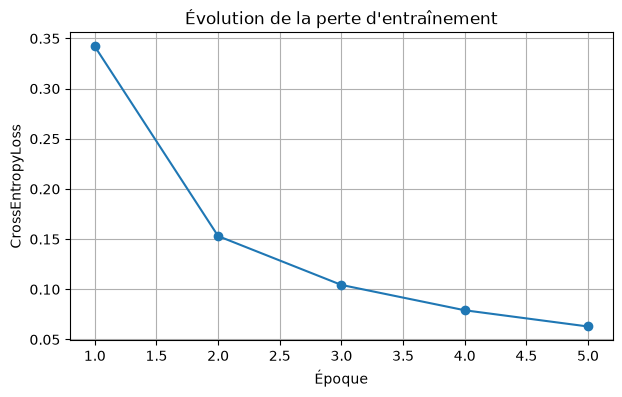

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), historique_loss, marker="o")
plt.xlabel("Époque")
plt.ylabel("CrossEntropyLoss")
plt.title("Évolution de la perte d'entraînement")
plt.grid(True)
plt.show()

## 6. Évaluation sur le jeu de test

On utilise `model.eval()` et `torch.no_grad()`.

Les classes prédites sont obtenues avec :

```python
predicted_classes = outputs.argmax(dim=1)
```

In [9]:
model.eval()

all_labels = []
all_predictions = []
all_images = []

with torch.no_grad():
    for batch_images, batch_labels in test_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        outputs = model(batch_images)
        predicted_classes = outputs.argmax(dim=1)

        all_labels.extend(batch_labels.cpu().numpy())
        all_predictions.extend(predicted_classes.cpu().numpy())
        all_images.append(batch_images.cpu())

all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_images = torch.cat(all_images, dim=0)

print("Nombre de prédictions :", len(all_predictions))

Nombre de prédictions : 10000


## 7. Accuracy, Precision, Recall et F1-Score

In [10]:
accuracy = accuracy_score(all_labels, all_predictions)
precision = precision_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)
recall = recall_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)
f1 = f1_score(
    all_labels, all_predictions,
    average="weighted",
    zero_division=0
)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

Accuracy  : 0.9756
Precision : 0.9757
Recall    : 0.9756
F1-Score  : 0.9756


## 8. Matrice de confusion

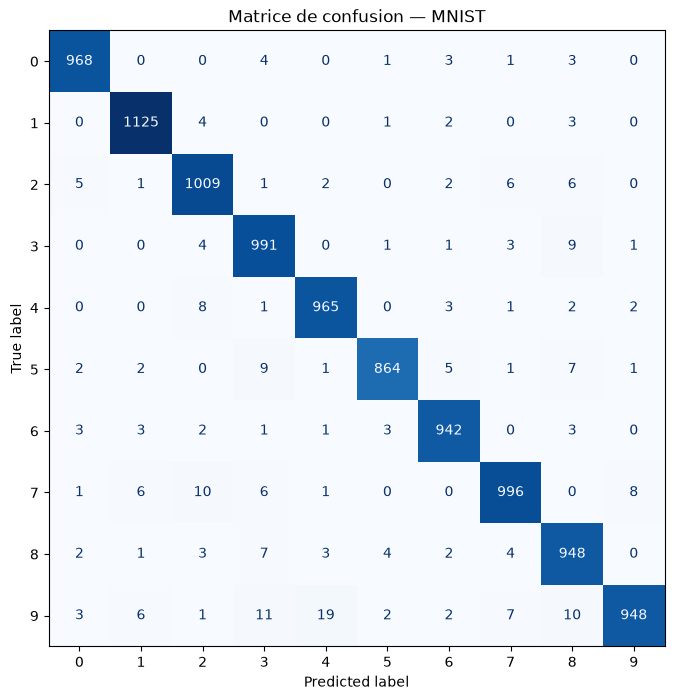

In [11]:
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

fig, ax = plt.subplots(figsize=(8, 8))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Matrice de confusion — MNIST")
plt.show()

## 9. Afficher quelques images mal classées

Nombre d'images mal classées : 244


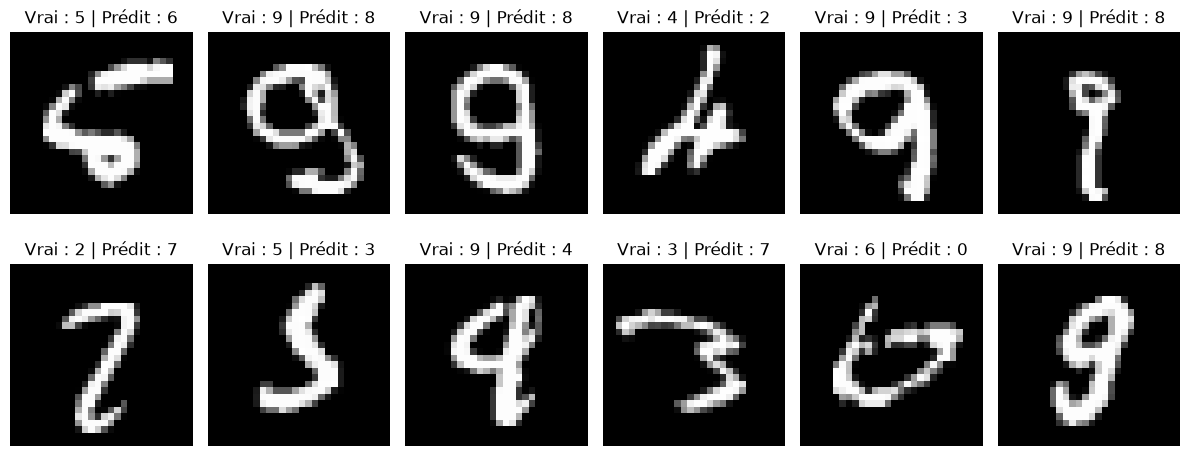

In [12]:
wrong_indices = np.where(all_labels != all_predictions)[0]

print("Nombre d'images mal classées :", len(wrong_indices))

n_show = min(12, len(wrong_indices))

fig, axes = plt.subplots(2, 6, figsize=(12, 5))
axes = axes.flatten()

for i in range(12):
    axes[i].axis("off")

for i in range(n_show):
    idx = wrong_indices[i]
    image = all_images[idx][0]

    axes[i].imshow(image.numpy(), cmap="gray", vmin=0, vmax=1)
    axes[i].set_title(
        f"Vrai : {all_labels[idx]} | Prédit : {all_predictions[idx]}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

## 10. Sauvegarder le modèle

On sauvegarde les paramètres appris avec `state_dict()`.

In [13]:
model_path = "mnist_mlp.pth"

torch.save(model.state_dict(), model_path)

print(f"Modèle sauvegardé dans : {model_path}")

Modèle sauvegardé dans : mnist_mlp.pth


## 11. Recharger le modèle

On recrée la même architecture, puis on recharge les paramètres sauvegardés. Cela permet de réutiliser le modèle sans refaire l'apprentissage.

In [14]:
loaded_model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

loaded_model.load_state_dict(torch.load(model_path, map_location=device))
loaded_model.eval()

print("Modèle rechargé avec succès.")

Modèle rechargé avec succès.


## 12. Vérifier une prédiction avec le modèle rechargé

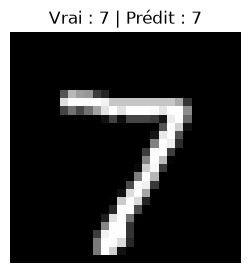

In [15]:
image_index = 0

with torch.no_grad():
    image = all_images[image_index].unsqueeze(0).to(device)
    output = loaded_model(image)
    prediction = output.argmax(dim=1).item()

true_label = all_labels[image_index]

plt.figure(figsize=(3, 3))
plt.imshow(all_images[image_index, 0].numpy(), cmap="gray", vmin=0, vmax=1)
plt.title(f"Vrai : {true_label} | Prédit : {prediction}")
plt.axis("off")
plt.show()

# Réponses / interprétation

### 1. Pourquoi utiliser des mini-lots ?
Les mini-lots permettent de traiter les données par petits groupes plutôt que toutes les images simultanément. Cela réduit l'utilisation de mémoire et permet de mettre à jour progressivement les paramètres du modèle.

### 2. Pourquoi `model.train()` ?
`model.train()` place le réseau en mode entraînement. C'est important pour les couches dont le comportement dépend du mode entraînement/évaluation.

### 3. Pourquoi `model.eval()` ?
`model.eval()` place le réseau en mode évaluation avant de tester le modèle.

### 4. Pourquoi `torch.no_grad()` ?
Il désactive le calcul des gradients pendant l'évaluation, ce qui évite des calculs inutiles et réduit la consommation de mémoire.

### 5. Pourquoi ne pas mettre Softmax avant `CrossEntropyLoss` ?
`CrossEntropyLoss` travaille directement avec les logits bruts produits par la dernière couche. Il n'est donc pas nécessaire d'ajouter `Softmax` avant la fonction de perte.

### 6. Que représente la matrice de confusion ?
Chaque ligne correspond à la vraie classe et chaque colonne à la classe prédite. La diagonale représente les classifications correctes ; les autres cases représentent les erreurs de classification.

### 7. Pourquoi sauvegarder le modèle ?
La sauvegarde permet de réutiliser un modèle déjà entraîné sans recommencer les cinq époques d'apprentissage.